[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sampriti-sr/MLP_Course/blob/kshitij-variant/docs/lifecycle/12-serving.ipynb)

# Packaging and Serving

<div class="admonition info">
<p class="admonition-title">What you will be able to do after this page</p>
<ul>
<li>Open the test set once, report the verdict honestly, and separate what held up from what did not.</li>
<li>Package a model with a card and a hash, and load it safely.</li>
<li>Serve through one validated function that is tested to reproduce the batch scores.</li>
<li>Choose the simplest serving style that meets the need.</li>
</ul>
</div>

**Prerequisites:** <a href="../11-interpretation/">Interpretation and Fairness</a>. **Dataset:** Online Retail II. **Time:** about 50 minutes.

In [1]:
try:
    import mlp_data
except ImportError:  # e.g. a fresh Colab runtime
    %pip install -q "mlp-course @ git+https://github.com/sampriti-sr/MLP_Course@kshitij-variant"
    import mlp_data

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mlp_data import load_retail, retail, style

style.apply()
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 14)
pd.set_option("display.float_format", "{:,.2f}".format)

## The situation

The model is chosen, interpreted and checked. Two things remain before anyone can use it: an **honest verdict** and a **form other systems can call**. They come in that order, because the model we ship must be the model we tested.

## The test verdict

Everything so far used the training and validation snapshots. The test snapshot (1 September 2011) has been locked away, and we have not looked at its labels once, not even their average. The protocol:

1. The final model is the logistic regression **refit on training and validation together** (more data, and it includes the most recent behaviour we can see). The embargo guarantees that no label window in that data reaches September.
2. We score the test snapshot **once**, in a single cell, and report whatever comes out.
3. We do not change the model in response. If we did, the test set would become a second validation set and we would have no honest number left.

Alongside the final model we score the two yardsticks that need no training: random calling and the "silent × valuable" rule.

In [2]:
from IPython.display import display
from mlp_data import models, serving
from mlp_data.metrics import at_risk_report, random_calling_report, bootstrap_interval, bootstrap_difference

cleaned = retail.clean_retail(load_retail())
sales, returns = cleaned.sales, cleaned.returns
sp = retail.build_splits(sales, returns, features="full")
train, valid, test = sp.train, sp.valid, sp.test
F = models.FEATURES

validated = models.make_logistic().fit(train[F], train["y"])                  # the model that validation judged
labelled = pd.concat([train, valid], ignore_index=True)
final = models.make_logistic().fit(labelled[F], labelled["y"])                # the model we will ship
print(f"final model fitted on {len(labelled):,} labelled customer-snapshots (train + validation); test set has {len(test):,} customers, untouched until now")

final model fitted on 21,234 labelled customer-snapshots (train + validation); test set has 4,323 customers, untouched until now


In [3]:
# ---- THE ONE LOOK AT THE TEST SET ----
pct = lambda s: s.rank(pct=True)
def verdict(model, frame, label):
    p = model.predict_proba(frame[F])[:, 1]
    v = frame["monetary"].to_numpy()
    q = at_risk_report(frame["y"], p, frame["monetary"], probabilities=True)
    m = at_risk_report(frame["y"], p, frame["monetary"], risk=(1 - p) * v, probabilities=True)
    return p, {"AUC": q["AUC"], "Brier score": q["brier"], "average predicted return rate": p.mean(), "actual return rate": frame["y"].mean(),
               "precision@200": m["precision@200"], "revenue@200 protected": m["revenue@200"], "revenue@200 % of the best possible": m["revenue@200 % of oracle"]}

p_val, on_validation = verdict(validated, valid, "validation")
p_test, on_test = verdict(final, test, "test")
rule_risk = (pct(test["recency_days"]) * pct(test["monetary"])).to_numpy()
rule = at_risk_report(test["y"], None, test["monetary"], risk=rule_risk)
rand = random_calling_report(test["y"], test["monetary"], train_rate=labelled["y"].mean())

fmt = {"AUC": "{:.3f}", "Brier score": "{:.3f}", "average predicted return rate": "{:.1%}", "actual return rate": "{:.1%}",
       "precision@200": "{:.1%}", "revenue@200 protected": "{:,.0f}", "revenue@200 % of the best possible": "{:.1%}"}
summary = pd.DataFrame({"validation (what we expected)": on_validation, "test (what happened)": on_test})
summary.apply(lambda col: [fmt[i].format(x) for i, x in col.items()])

,validation (what we expected),test (what happened)
AUC,0.796,0.767
Brier score,0.172,0.227
average predicted return rate,31.1%,31.9%
actual return rate,36.6%,49.5%
precision@200,43.5%,28.0%
revenue@200 protected,"571,074","340,926"
revenue@200 % of the best possible,62.9%,49.6%


In [4]:
test_risk = (1 - p_test) * test["monetary"].to_numpy()
ci_auc = bootstrap_interval(test["y"], p_test, test["monetary"], metric="AUC", n_boot=300)
ci_rev = bootstrap_interval(test["y"], p_test, test["monetary"], metric="revenue@200", risk=test_risk, n_boot=300)
vs_rule = bootstrap_difference(test["y"], test["monetary"], test_risk, rule_risk, metric="revenue@200", n_boot=300)

print(f"test AUC {on_test['AUC']:.3f}  (90% interval {ci_auc[0]:.3f} to {ci_auc[1]:.3f})")
print(f"test revenue@200: model {on_test['revenue@200 protected']:,.0f} (90% interval {ci_rev[0]:,.0f} to {ci_rev[1]:,.0f})   "
      f"| silent x valuable rule {rule['revenue@200']:,.0f}   | random calling {rand['revenue@200']:,.0f}   | best possible {rand['revenue@200 oracle']:,.0f}")
print(f"model minus the no-model rule: {vs_rule['mean']:+,.0f} (90% interval {vs_rule['low']:+,.0f} to {vs_rule['high']:+,.0f}); the model is ahead in {vs_rule['share_a_better']:.0%} of resamples")
print(f"calibration: the model predicted a {p_test.mean():.0%} return rate; {test['y'].mean():.0%} of customers actually returned")

test AUC 0.767  (90% interval 0.755 to 0.780)
test revenue@200: model 340,926 (90% interval 242,550 to 446,898)   | silent x valuable rule 306,970   | random calling 74,310   | best possible 686,861
model minus the no-model rule: +33,844 (90% interval -9,810 to +74,096); the model is ahead in 91% of resamples
calibration: the model predicted a 32% return rate; 50% of customers actually returned


**Reading the verdict.** The result has two halves, and they tell different stories.

**The ranking held up.** AUC slipped a little from validation (the interval is below the validation figure but well above chance), and in money the call list still protects several times what random calling would. The thing we use to make the call list, the *order* of customers, survives. **Against the simple no-model rule, though, it is not demonstrably better**: it comes out ahead by a few tens of thousands of pounds, in most resamples, but the interval includes zero. On money the two are tied.

**The probabilities did not.** On validation the model under-predicted the return rate by a few points. On test it predicted about **32%** when roughly **half** of customers came back. Every probability is too low, and the Brier score is far worse than on validation. The reason is the one the exploration page flagged and our evidence kept hinting at: the test window runs from 1 September to the end of November, the **autumn peak** (Page 4), when almost everyone buys more. We trained on December to May and validated in June to August, quiet seasons, and the model has simply never seen the behaviour of a peak.

Let us look at it by group, as we did on validation.

In [5]:
groups = {"all customers": pd.Series("all", index=test.index),
          "tenure under 90 days": test["tenure_days"].lt(90).map({True: "under 90 days", False: "older"}),
          "country": test["is_uk"].map({1: "UK", 0: "outside UK"})}
rows = []
for name, g in groups.items():
    for k, idx in g.groupby(g).groups.items():
        mask = test.index.isin(idx)
        rows.append({"group": f"{name}: {k}" if name != "all customers" else "all customers", "customers": int(mask.sum()),
                     "actually returned": test.loc[mask, "y"].mean(), "model predicted": p_test[mask].mean()})
by_group = pd.DataFrame(rows).set_index("group")
by_group.assign(**{"actually returned": by_group["actually returned"].map("{:.1%}".format), "model predicted": by_group["model predicted"].map("{:.1%}".format),
                   "gap (points)": ((by_group["actually returned"] - by_group["model predicted"]) * 100).map("{:+.1f}".format)})

,customers,actually returned,model predicted,gap (points)
group,,,,
all customers,4323,49.5%,31.9%,+17.6
tenure under 90 days: older,4016,49.4%,32.6%,+16.8
tenure under 90 days: under 90 days,307,51.1%,23.1%,+28.1
country: UK,3936,49.2%,31.3%,+18.0
country: outside UK,387,52.2%,38.7%,+13.5


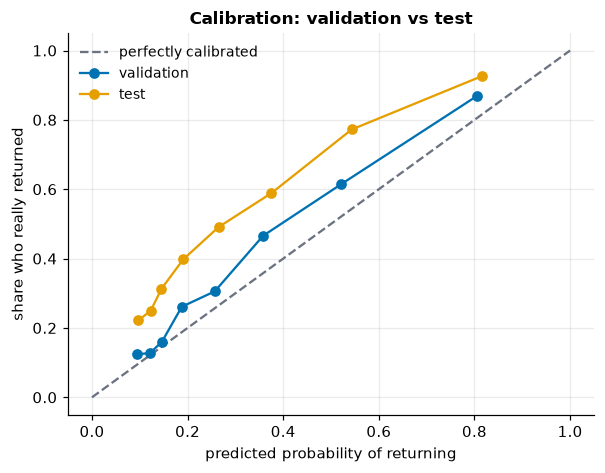

In [6]:
from sklearn.calibration import calibration_curve
fig, ax = plt.subplots(figsize=(5.6, 4.4))
ax.plot([0, 1], [0, 1], color=style.GREY, ls="--", label="perfectly calibrated")
for label, y, p, color in [("validation", valid["y"], p_val, style.BLUE), ("test", test["y"], p_test, style.ORANGE)]:
    obs, pred = calibration_curve(y, p, n_bins=8, strategy="quantile")
    ax.plot(pred, obs, marker="o", color=color, label=label)
ax.set(xlabel="predicted probability of returning", ylabel="share who really returned", title="Calibration: validation vs test"); ax.legend()
plt.tight_layout(); plt.show()
assert on_test["actual return rate"] - on_test["average predicted return rate"] > 0.10          # the large calibration gap discussed in the text
assert vs_rule["low"] < 0 < vs_rule["high"] and vs_rule["share_a_better"] > 0.8                    # the model and the no-model rule are tied on money: ahead in most resamples, but not demonstrably

**Reading the group table and the chart.** The shortfall is everywhere: every group returned far more than the model predicted, and the **orange test curve sits well above the diagonal** along its whole length while the blue validation curve hugs it. New customers are the extreme case, predicted at under a quarter and actually returning about half the time.

What this means in practice:

- **Use the model for the order, not the odds.** The call list is built from a ranking, and a uniform shift in probabilities mostly preserves rankings. That is why the money held up while calibration broke.
- **Do not quote its probabilities as forecasts** in a season it has not seen. Any "expected gain" computed from them (as on the evaluation page) would be too pessimistic about how many customers return.
- **This is drift**, and it needs a plan, not a shrug: seasonal features once we have more than one year of history, recalibration on recent data, and monitoring that notices the moment the base rate moves. That is the next page.

The honest summary is the one we would give the business: *"It ranks customers about as well as the simple rule and far better than chance, but its probabilities are unreliable in the busy season, and we should not trust its absolute numbers."*

## Ship the model, or the simple rule?

On the test window the model and the no-model "silent × valuable" rule are **tied on money**: the model is ahead by a few tens of thousands of pounds, but the interval spans zero. That is the same message as the baselines page, now confirmed on data nobody tuned against: *the decision rule matters far more than the model*. So it is fair to ask whether we need the model at all.

| | The rule | The model |
|---|---|---|
| **Money protected (test)** | about the same | about the same |
| **Cost to run and explain** | trivial | small: a fitted file, a pipeline, a check |
| **Gives a probability per customer** | no | yes (unreliable in a busy season, as we just saw) |
| **Can improve with better inputs** | no | yes |

Neither choice is wrong. We ship the model, because it is already built and tested, scores everyone in a fraction of a second, and gives us something to improve. But we ship it **with the rule alongside as a standing benchmark**: each month we score both, and if the model stops beating or matching the rule, that is an alarm worth acting on. A model that cannot beat a free rule is not earning its keep. The next page builds that guardrail into the monitoring.

## From notebook to artifact

A fitted model in a notebook cannot be called by anyone else. To ship it we save two things side by side: the **model file** and a **card** describing it. The card records what it is, how it was trained, how good it was, the exact feature list, and a **fingerprint of the file**, so we can tell if it is later corrupted or swapped.

In [7]:
import tempfile, json
from pathlib import Path

workdir = Path(tempfile.mkdtemp(prefix="mlp_model_"))
card = serving.save_model(
    final, workdir, "repurchase_logistic_v1",
    metrics={"test_auc": on_test["AUC"], "test_revenue_pct_of_best_possible": on_test["revenue@200 % of the best possible"], "test_average_predicted": on_test["average predicted return rate"], "test_actual": on_test["actual return rate"]},
    training={"snapshots": [str(c.date()) for c in retail.TRAIN_CUTOFFS] + [str(retail.VALID_CUTOFF.date())], "rows": int(len(labelled)),
              "horizon_days": retail.HORIZON_DAYS, "lookback_days": retail.LOOKBACK_DAYS},
    notes="Ranks active customers by value at risk for the monthly call list. Use the ORDER, not the probabilities: they under-predict in the autumn peak.")
print("files written:", sorted(p.name for p in workdir.iterdir()), f"| model file {card['size_bytes'] / 1024:.0f} KB")
{k: card[k] for k in ["name", "sha256", "features", "notes"]} | {"training": card["training"], "metrics": {k: round(v, 3) for k, v in card["metrics"].items()}}

files written: ['repurchase_logistic_v1.card.json', 'repurchase_logistic_v1.joblib'] | model file 7 KB


{'name': 'repurchase_logistic_v1',
 'sha256': '139b73b8b494b66fcb7d0fb2cfc26ec632cc858d4ec525ee81c8b70d2b80f22a',
 'features': ['recency_days',
  'frequency',
  'monetary',
  'monetary_90d',
  'avg_order_value',
  'items_per_order',
  'n_products',
  'freq_30d',
  'freq_90d',
  'freq_180d',
  'freq_prev_90d',
  'n_returns',
  'tenure_days',
  'avg_gap_days',
  'recency_over_gap',
  'trend_90d',
  'return_value_share',
  'is_uk'],
 'notes': 'Ranks active customers by value at risk for the monthly call list. Use the ORDER, not the probabilities: they under-predict in the autumn peak.',
 'training': {'snapshots': ['2010-12-01',
   '2011-01-01',
   '2011-02-01',
   '2011-03-01',
   '2011-06-01'],
  'rows': 21234,
  'horizon_days': 90,
  'lookback_days': 365},
 'metrics': {'test_auc': 0.767,
  'test_revenue_pct_of_best_possible': 0.496,
  'test_average_predicted': np.float64(0.319),
  'test_actual': np.float64(0.495)}}

Now load it back. `load_model` recomputes the file's hash and **refuses to load** a file that no longer matches its card.

In [8]:
loaded, loaded_card = serving.load_model(workdir, "repurchase_logistic_v1")
assert np.allclose(loaded.predict_proba(test[F])[:, 1], p_test)                 # identical predictions after the round trip

(workdir / "repurchase_logistic_v1.joblib").write_bytes((workdir / "repurchase_logistic_v1.joblib").read_bytes() + b"tampered")
try:
    serving.load_model(workdir, "repurchase_logistic_v1")
except ValueError as e:
    print("refused:", e)

refused: repurchase_logistic_v1.joblib does not match the hash in its card: the file was changed or corrupted; refusing to load it


<div class="admonition danger">
<p class="admonition-title">Model files are code, in disguise</p>
<p>A saved scikit-learn model is a <em>pickle</em>, and loading a pickle can execute arbitrary code. Never load a model file from a source you do not trust. The hash check catches corruption and a swapped file; it does not defend against someone who can change <em>both</em> the file and its card. In production keep the expected hash somewhere separate, or sign the artifact.</p>
</div>

## Serving: one function, tested against the batch results

Whoever uses the model should not need to know about snapshots, feature windows or the order of our columns. They hand over the transactions and a date, and receive a ranked list. That is `score_customers`, which validates its inputs, builds features using **only events before the date**, and returns the ranking.

The key test is **train/serve consistency**: scoring through this function must give exactly the numbers we got in the batch evaluation. If they differed, the shipped model would behave differently from the one we validated, a common and very hard-to-spot failure.

In [9]:
scores = serving.score_customers(loaded, sales, returns, retail.TEST_CUTOFF)

batch = pd.DataFrame({"customer_id": test["customer_id"].to_numpy(), "p_batch": p_test}).set_index("customer_id")
check = scores.set_index("customer_id").join(batch)
assert len(scores) == len(test) and np.allclose(check["p_return"], check["p_batch"])
print(f"serving reproduces the batch scores for all {len(scores):,} customers")

# Data from after the cutoff must be unable to change a score:
past_only = serving.score_customers(loaded, sales[sales["invoice_date"] < retail.TEST_CUTOFF], returns, retail.TEST_CUTOFF)
pd.testing.assert_frame_equal(scores, past_only)
print("scores are identical when every record after the cutoff is deleted")

serving reproduces the batch scores for all 4,323 customers


scores are identical when every record after the cutoff is deleted


That second check is the time-travel test from the feature page, now guarding the *serving* path. Finally, the output people will actually use: the monthly call list.

In [10]:
import time
t0 = time.perf_counter(); serving.score_customers(loaded, sales, returns, retail.TEST_CUTOFF); seconds = time.perf_counter() - t0

call_list = scores.head(200)[["call_rank", "customer_id", "p_return", "value_at_risk", "past_year_spend", "orders", "days_since_last_order"]]
print(f"scoring {len(scores):,} customers end to end took {seconds:.1f} seconds (including feature building)")
call_list.head(8).assign(p_return=call_list["p_return"].map("{:.0%}".format), value_at_risk=call_list["value_at_risk"].map("{:,.0f}".format),
                         past_year_spend=call_list["past_year_spend"].map("{:,.0f}".format), days_since_last_order=call_list["days_since_last_order"].round(0).astype(int))

scoring 4,323 customers end to end took 0.3 seconds (including feature building)


,call_rank,customer_id,p_return,value_at_risk,past_year_spend,orders,days_since_last_order
0,1,15749,41%,"26,448","44,534",3,135
1,2,12454,22%,"10,087","12,931",3,296
2,3,16754,42%,"9,373","16,088",4,272
3,4,13687,30%,"8,280","11,881",1,338
4,5,12357,33%,"7,572","11,230",1,289
5,6,12409,45%,"6,258","11,438",2,82
6,7,12590,38%,"5,772","9,341",1,111
7,8,15523,32%,"5,770","8,449",4,288


## Choosing how to serve it

| Style | Fits when | For us |
|---|---|---|
| **Batch** (a scheduled job writes a file or table) | decisions are made on a schedule, scores can be a day old | **Yes.** The account managers work from a monthly list. |
| **Real-time API** (a service answers one request at a time) | a user or system needs an answer within milliseconds | No. Nobody is waiting on a screen. |

Start with the simplest thing that meets the need. If a real-time service were required, the same `score_customers` function would sit behind a small web endpoint. An illustrative sketch (not run here; it needs a web framework installed):

```python
# Illustrative only. Requires: pip install fastapi uvicorn
from fastapi import FastAPI, HTTPException
import pandas as pd
from mlp_data import serving

app = FastAPI()
model, card = serving.load_model("models/", "repurchase_logistic_v1")      # verified once, at start-up

@app.post("/score")
def score(transactions: list[dict], cutoff: str):
    try:
        return serving.score_customers(model, pd.DataFrame(transactions), pd.DataFrame(), cutoff).head(200).to_dict("records")
    except ValueError as e:                    # bad input -> a clear 422, never a stack trace
        raise HTTPException(status_code=422, detail=str(e))
```

## Make bad input fail loudly

Production data is messier than anything in a notebook. `score_customers` checks its inputs and refuses, with a readable message, rather than failing deep inside the features or, worse, returning plausible nonsense. Three of the cases it covers:

In [11]:
cases = {"a required column is missing": (sales.drop(columns=["revenue"]), returns, "2011-09-01"),
         "the date is not a date": (sales, returns, "next Tuesday"),
         "the data is out of date for that cutoff": (sales, returns, "2012-06-01")}
for label, (s_, r_, c_) in cases.items():
    try:
        serving.score_customers(loaded, s_, r_, c_)
    except ValueError as e:
        print(f"{label}:\n    -> {e}")

a required column is missing:
    -> sales is missing required columns: ['revenue']
the date is not a date:
    -> cutoff 'next Tuesday' is not a date
the data is out of date for that cutoff:
    -> cutoff 2012-06-01 is after the last record (2011-12-09); the data is stale


## Check yourself

<details class="question">
<summary>1. The model's probabilities were far too low on test, yet its call list still protected several times the revenue of random calling. How can both be true?</summary>

The call list depends on the **order** of customers by value at risk, not on the absolute probabilities. A season-wide shift that makes every customer more likely to return pushes all probabilities down together and mostly preserves the order. So the ranking (and the money it protects) survives while calibration fails. This is why we say: use the order, not the odds.

</details>

<details class="question">
<summary>2. We refit the final model on training plus validation. Why is that safe for the test set, and what would make it unsafe?</summary>

It is safe because the embargo means no label window in the training or validation snapshots reaches the test period, so the refit data contains nothing about September to November. It would be unsafe if the refit data included any test-period information, or if we changed the model after seeing the test score (turning the test set into a second validation set).

</details>

<details class="question">
<summary>3. Why test that serving reproduces the batch scores, when it uses the same model file?</summary>

Because the model is only part of the pipeline. The *features* are computed by code on the serving path, and a small difference in how they are built (a different window, a missing cleaning step, a different column order) changes the scores without any error. This train/serve skew is one of the commonest silent failures, so we assert exact equality on real data.

</details>

## Exercise

<details class="question">
<summary>Try scoring as of 31 December 2011. What happens, and why is refusing the right behaviour?</summary>

```python
serving.score_customers(loaded, sales, returns, "2011-12-31")
```

It raises a `ValueError` saying the cutoff is after the last record and the data is stale. The data ends on 9 December 2011, so a score "as of 31 December" would silently ignore three weeks of activity and produce a confident-looking list from an out-of-date picture. A clear refusal beats a plausible wrong answer.

</details>

## Recap

- **Open the test set once**, after every decision is made, and report it whatever it says. Ours showed the ranking surviving and the probabilities failing, because the model had never seen the autumn peak.
- Use the model for what it still does well (**the order**) and say plainly what it does not (**the odds**). When a free rule ties the model on money, ship the model only with the rule as a standing benchmark.
- Package the model with a **card** (features, training data, metrics, fingerprint) and **verify the hash on load**. Model files are pickles: only load files you trust.
- Serve through **one function** that validates its inputs, uses only information before the cutoff, and is **tested to reproduce the batch scores**.
- Pick the simplest serving style that meets the need (here, a monthly batch job), and make bad input fail with a clear message.

**Next:** *Monitoring and drift*, where we build the alarm that would have caught the base-rate shift before anyone relied on the numbers.